
# Notebook 01: Exploratory Data Analysis (EDA) & Preprocessing
## Graduation Thesis: CNN-BiLSTM-Attention Model for Electricity Load Forecasting in a Microgrid

**Dataset:** Building Data Genome Project 2 (BDG2) - Campus Microgrid  
**Source:** Kaggle - Clayton Miller et al. (Nature Scientific Data, 2020)

**Contents:**
1. Load the BDG2 dataset (electricity, metadata, and weather)
2. Construct a campus microgrid (aggregating multiple educational buildings)
3. Perform Exploratory Data Analysis (EDA)
4. Integrate weather data
5. Perform feature engineering
6. Normalize data using MinMaxScaler
7. Create sliding windows
8. Split data into training, validation, and test sets
9. Save the preprocessed data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.grid'] = True

PROJECT_DIR = os.path.dirname(os.path.abspath('__file__')) if '__file__' in dir() else os.getcwd()
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print('Setup completed!')
print(f'Project directory: {PROJECT_DIR}')

Setup completed!
Project directory: /Users/doquynhhuong/Documents/Đồ án tốt nghiệp 2025.2/v2/v2



## 1. Load the BDG2 Dataset

**Dataset:** Building Data Genome Project 2
- 1,578 electricity meters across 1,636 non-residential buildings
- Frequency: Hourly (1-hour intervals)
- Time period: 2 years (2016–2017)
- Unit: kWh (equivalent to average power in kW over each hour)

In [2]:
# Load electricity data
df_elec = pd.read_csv(
    os.path.join(DATA_DIR, 'electricity_cleaned.csv'),
    parse_dates=['timestamp'],
    index_col='timestamp'
)

# Load metadata
meta = pd.read_csv(os.path.join(DATA_DIR, 'metadata.csv'))

# Load weather
df_weather = pd.read_csv(
    os.path.join(DATA_DIR, 'weather.csv'),
    parse_dates=['timestamp']
)

print(f'Electricity: {df_elec.shape} ({df_elec.shape[1]} tòa nhà)')
print(f'Time: {df_elec.index.min()} -> {df_elec.index.max()}')
print(f'Metadata: {meta.shape}')
print(f'Weather: {df_weather.shape}')

Electricity: (17544, 1578) (1578 tòa nhà)
Time: 2016-01-01 00:00:00 -> 2017-12-31 23:00:00
Metadata: (1636, 32)
Weather: (331166, 10)


## 2. Construct a Campus Microgrid

Aggregate electricity consumption from multiple educational buildings at the same site, **Robin** (London, UK), to simulate the electricity load of a campus microgrid.

In [3]:
# Filter educational buildings at the Robin site
robin_edu = meta[(meta['site_id'] == 'Robin') & (meta['primaryspaceusage'] == 'Education')]
robin_ids = [b for b in robin_edu['building_id'].tolist() if b in df_elec.columns]
print(f'Number of educational buildings at Robin: {len(robin_ids)}')

# Select buildings with high-quality data
good_buildings = []
for b in robin_ids:
    col = df_elec[b]
    nan_pct = col.isna().sum() / len(col) * 100
    mean_val = col.mean()
    if nan_pct < 5 and mean_val > 50:
        good_buildings.append({
            'id': b,
            'mean_kW': mean_val,
            'max_kW': col.max(),
            'nan_pct': nan_pct
        })

good_buildings = sorted(good_buildings, key=lambda x: x['mean_kW'], reverse=True)

print(f'\nNumber of buildings meeting the criteria: {len(good_buildings)}')
print(f'\nTop 10 buildings:')
for i, b in enumerate(good_buildings[:10], 1):
    print(f"  {i}. {b['id']}: mean={b['mean_kW']:.0f} kW, max={b['max_kW']:.0f} kW, NaN={b['nan_pct']:.1f}%")

# Select 7 buildings to construct the campus microgrid
selected_ids = [b['id'] for b in good_buildings[:7]]
print(f'\n=> Selected {len(selected_ids)} buildings for the campus microgrid')

Number of educational buildings at Robin: 22

Number of buildings meeting the criteria: 20

Top 10 buildings:
  1. Robin_education_Leslie: mean=886 kW, max=1544 kW, NaN=0.0%
  2. Robin_education_Derick: mean=529 kW, max=962 kW, NaN=0.0%
  3. Robin_education_Margarito: mean=529 kW, max=948 kW, NaN=0.0%
  4. Robin_education_So: mean=491 kW, max=711 kW, NaN=0.0%
  5. Robin_education_Derrick: mean=403 kW, max=682 kW, NaN=0.0%
  6. Robin_education_Madeline: mean=362 kW, max=679 kW, NaN=0.0%
  7. Robin_education_Julius: mean=346 kW, max=719 kW, NaN=0.0%
  8. Robin_education_Audrea: mean=287 kW, max=588 kW, NaN=0.0%
  9. Robin_education_Terrance: mean=264 kW, max=498 kW, NaN=0.0%
  10. Robin_education_Mercedes: mean=255 kW, max=607 kW, NaN=0.0%

=> Selected 7 buildings for the campus microgrid


In [4]:
# Calculate the total electricity load of the campus microgrid
campus_df = df_elec[selected_ids].copy()
campus_df = campus_df.interpolate(method='linear').ffill().bfill()

df_hourly = pd.DataFrame()
df_hourly['load_kW'] = campus_df.sum(axis=1)

print(f'=== CAMPUS MICROGRID STATISTICS ===')
print(f'Number of buildings: {len(selected_ids)}')
print(f'Dataset shape: {df_hourly.shape}')
print(f'Time range: {df_hourly.index.min()} -> {df_hourly.index.max()}')
print(f'\nElectricity load statistics (kW):')
print(f'  Mean:  {df_hourly["load_kW"].mean():.0f} kW')
print(f'  Std:   {df_hourly["load_kW"].std():.0f} kW')
print(f'  Min:   {df_hourly["load_kW"].min():.0f} kW')
print(f'  Max:   {df_hourly["load_kW"].max():.0f} kW')
print(f'  CV:    {df_hourly["load_kW"].std()/df_hourly["load_kW"].mean():.3f}')
print(f'  NaN:   {df_hourly["load_kW"].isna().sum()}')

df_hourly.describe()

=== CAMPUS MICROGRID STATISTICS ===
Number of buildings: 7
Dataset shape: (17544, 1)
Time range: 2016-01-01 00:00:00 -> 2017-12-31 23:00:00

Electricity load statistics (kW):
  Mean:  3545 kW
  Std:   538 kW
  Min:   1349 kW
  Max:   5417 kW
  CV:    0.152
  NaN:   0


,load_kW
count,17544.000000
mean,3545.101952
std,538.198954
min,1349.350000
25%,3159.524975
50%,3386.979600
75%,3886.786800
max,5417.338000


## 3. Exploratory Data Analysis (EDA)

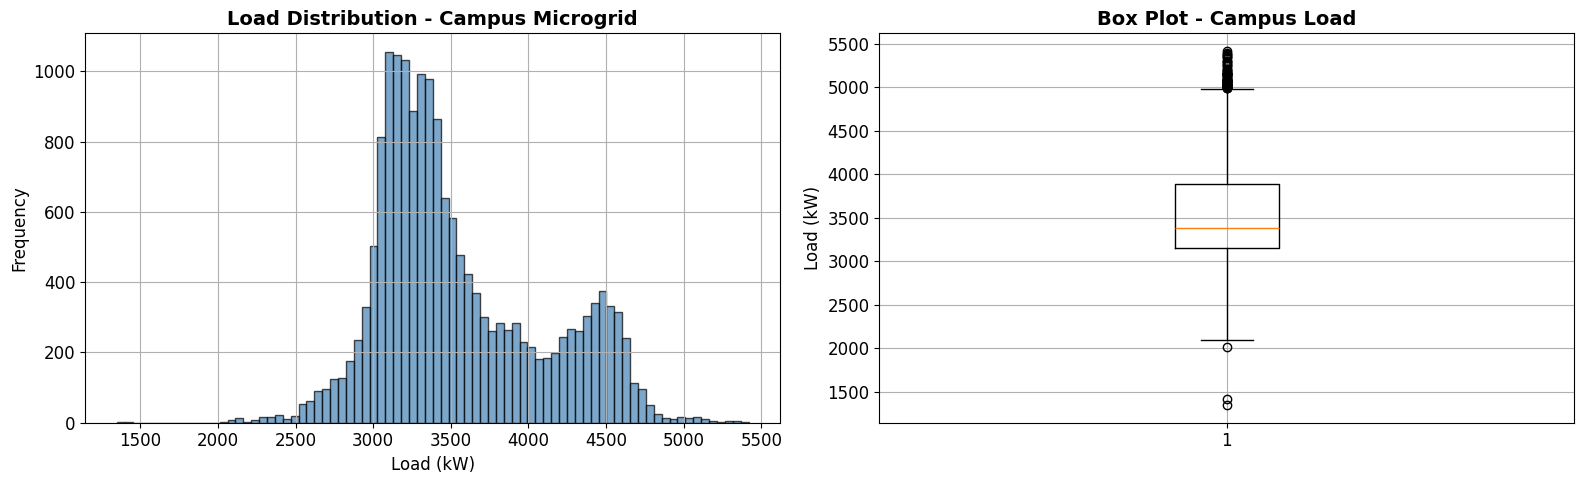

Saved: results/eda_distribution.png


In [5]:
# 3.1 Electricity Load Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(df_hourly['load_kW'], bins=80, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Load Distribution - Campus Microgrid', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Load (kW)')
axes[0].set_ylabel('Frequency')

axes[1].boxplot(df_hourly['load_kW'], vert=True)
axes[1].set_title('Box Plot - Campus Load', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Load (kW)')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/eda_distribution.png')

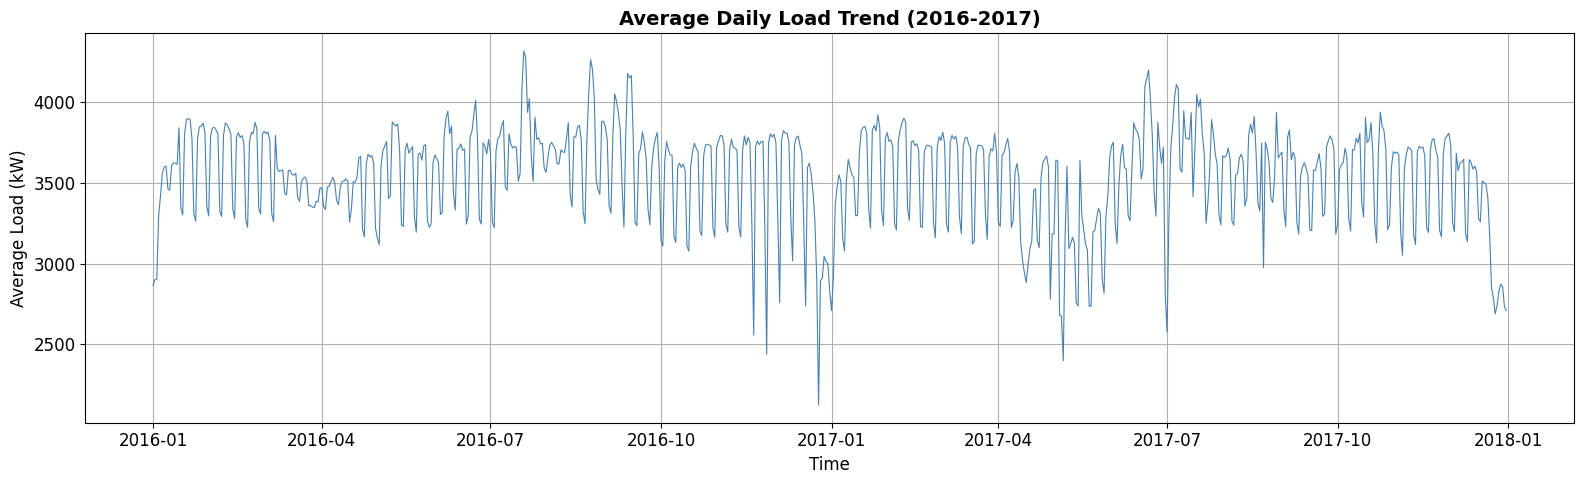

Saved: results/eda_daily_trend.png


In [6]:
# 3.2 Electricity Load Trend Over Time
daily = df_hourly['load_kW'].resample('D').mean()

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(daily.index, daily.values, color='steelblue', linewidth=0.8)
ax.set_title('Average Daily Load Trend (2016-2017)', fontsize=14, fontweight='bold')
ax.set_xlabel('Time')
ax.set_ylabel('Average Load (kW)')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_daily_trend.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/eda_daily_trend.png')

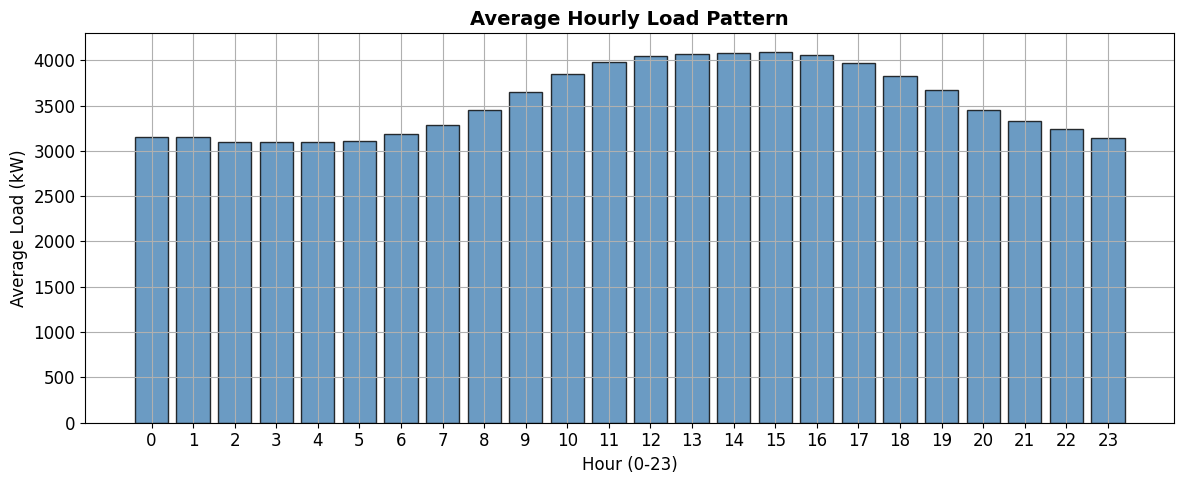

Saved: results/eda_hourly_pattern.png


In [7]:
# 3.3 Hourly Load Pattern Throughout the Day
hourly_pattern = df_hourly.groupby(df_hourly.index.hour)['load_kW'].mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(hourly_pattern.index, hourly_pattern.values, color='steelblue', edgecolor='black', alpha=0.8)
ax.set_title('Average Hourly Load Pattern', fontsize=14, fontweight='bold')
ax.set_xlabel('Hour (0-23)')
ax.set_ylabel('Average Load (kW)')
ax.set_xticks(range(24))
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_hourly_pattern.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/eda_hourly_pattern.png')

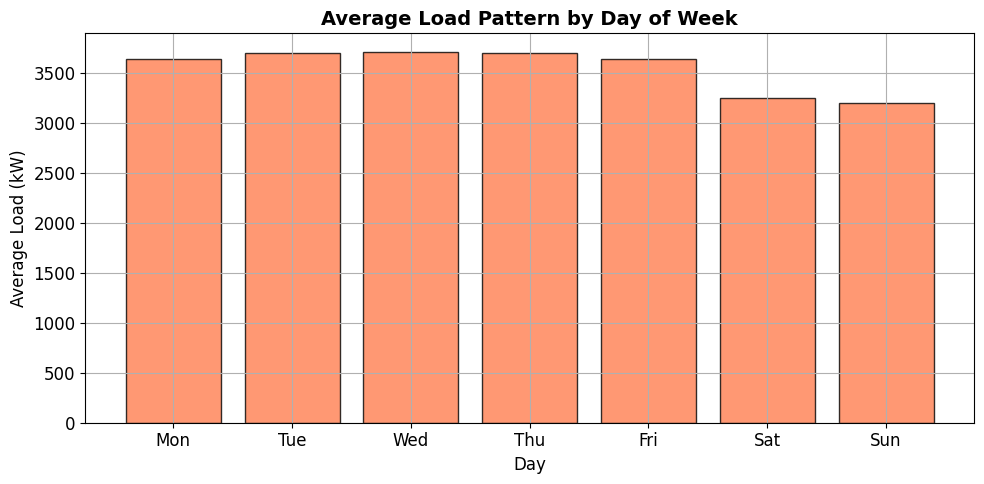

Saved: results/eda_weekly_pattern.png


In [8]:
# 3.4 Weekly Load Pattern
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekly_pattern = df_hourly.groupby(df_hourly.index.dayofweek)['load_kW'].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(7), weekly_pattern.values, color='coral', edgecolor='black', alpha=0.8)
ax.set_title('Average Load Pattern by Day of Week', fontsize=14, fontweight='bold')
ax.set_xlabel('Day')
ax.set_ylabel('Average Load (kW)')
ax.set_xticks(range(7))
ax.set_xticklabels(day_names)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_weekly_pattern.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/eda_weekly_pattern.png')

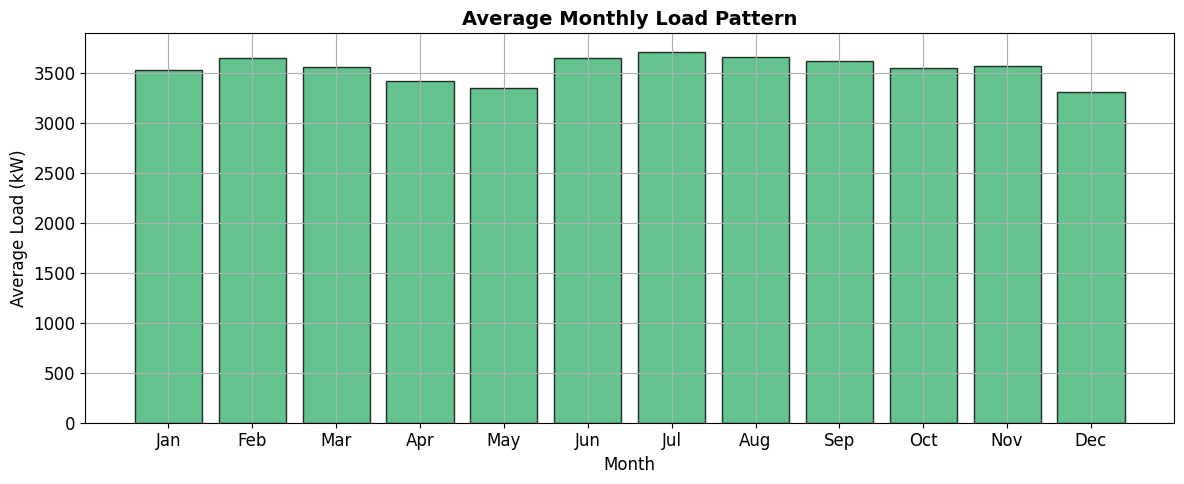

Saved: results/eda_monthly_pattern.png


In [9]:
# 3.5 Monthly Load Pattern
monthly_pattern = df_hourly.groupby(df_hourly.index.month)['load_kW'].mean()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(monthly_pattern.index, monthly_pattern.values, color='mediumseagreen', edgecolor='black', alpha=0.8)
ax.set_title('Average Monthly Load Pattern', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Average Load (kW)')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_monthly_pattern.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/eda_monthly_pattern.png')

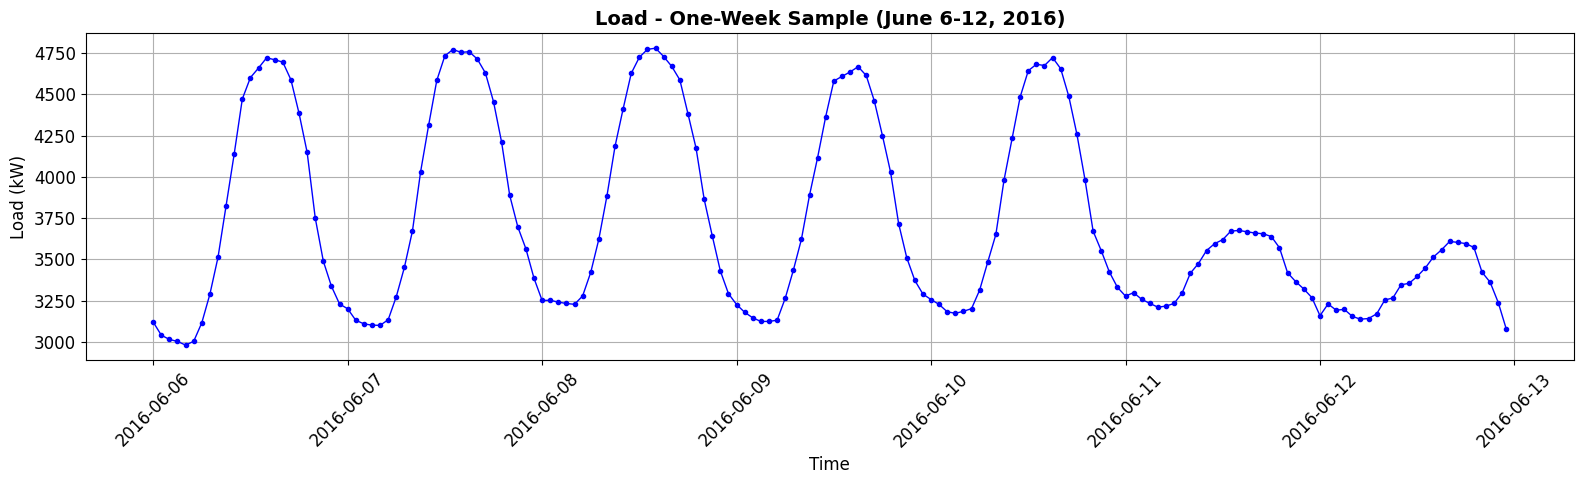

Saved: results/eda_week_sample.png


In [10]:
# 3.6 One-Week Load Data Sample
week_data = df_hourly['load_kW']['2016-06-06':'2016-06-12']

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(week_data.index, week_data.values, 'b-o', markersize=3, linewidth=1)
ax.set_title('Load - One-Week Sample (June 6-12, 2016)', fontsize=14, fontweight='bold')
ax.set_xlabel('Time')
ax.set_ylabel('Load (kW)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_week_sample.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/eda_week_sample.png')

## 4. Weather Data Integration

In [11]:

# Filter weather data for the Robin site
robin_weather = df_weather[df_weather['site_id'] == 'Robin'].copy()
robin_weather.set_index('timestamp', inplace=True)
robin_weather.index = pd.to_datetime(robin_weather.index)
robin_weather = robin_weather.drop(columns=['site_id'])

# Keep only columns with sufficient data
weather_cols = ['airTemperature', 'dewTemperature', 'seaLvlPressure', 'windSpeed']
robin_weather = robin_weather[weather_cols]
robin_weather = robin_weather.interpolate(method='linear').ffill().bfill()

# Merge weather data with electricity load data
df_hourly = df_hourly.join(robin_weather, how='left')
df_hourly[weather_cols] = df_hourly[weather_cols].interpolate(method='linear').ffill().bfill()

print(f'Dataset shape after merging weather data: {df_hourly.shape}')
print(f'Remaining NaN values: {df_hourly.isnull().sum().sum()}')
print(f'\nColumns: {list(df_hourly.columns)}')
df_hourly.head()

Dataset shape after merging weather data: (17544, 5)
Remaining NaN values: 0

Columns: ['load_kW', 'airTemperature', 'dewTemperature', 'seaLvlPressure', 'windSpeed']


,load_kW,airTemperature,dewTemperature,seaLvlPressure,windSpeed
timestamp,,,,,
2016-01-01 00:00:00,1418.7326,3.8,2.4,1020.9,3.1
2016-01-01 01:00:00,2804.2150,3.7,2.4,1021.6,2.6
2016-01-01 02:00:00,2808.3650,2.6,1.9,1021.9,0.0
2016-01-01 03:00:00,2807.2150,2.0,1.2,1022.3,1.5
2016-01-01 04:00:00,2834.3650,2.3,1.8,1022.7,1.5


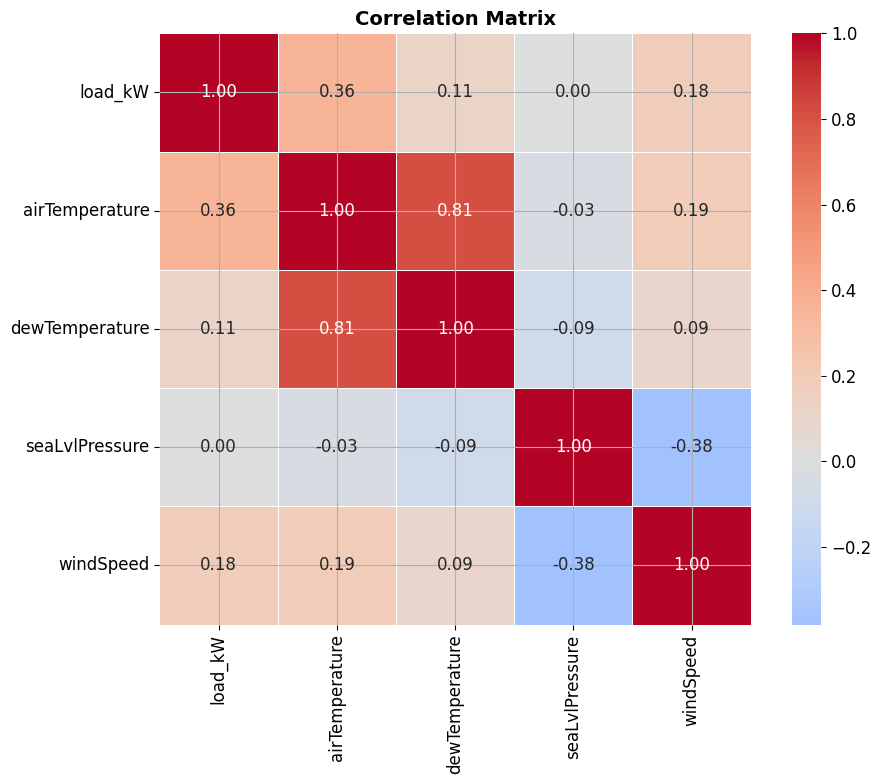

Saved: results/eda_correlation.png


In [12]:

# 3.7 Correlation Matrix
fig, ax = plt.subplots(figsize=(10, 8))
corr = df_hourly.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            square=True, linewidths=0.5)
ax.set_title('Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'eda_correlation.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/eda_correlation.png')


## 5. Feature Engineering

In [13]:

df_feat = df_hourly.copy()

# === 5.1 Temporal Features (Cyclical Encoding) ===
df_feat['hour_sin'] = np.sin(2 * np.pi * df_feat.index.hour / 24)
df_feat['hour_cos'] = np.cos(2 * np.pi * df_feat.index.hour / 24)
df_feat['dow_sin'] = np.sin(2 * np.pi * df_feat.index.dayofweek / 7)
df_feat['dow_cos'] = np.cos(2 * np.pi * df_feat.index.dayofweek / 7)
df_feat['month_sin'] = np.sin(2 * np.pi * df_feat.index.month / 12)
df_feat['month_cos'] = np.cos(2 * np.pi * df_feat.index.month / 12)

# === 5.2 Lag Features ===
for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
    df_feat[f'lag_{lag}h'] = df_feat['load_kW'].shift(lag)

# === 5.3 Rolling Statistics ===
for window in [6, 12, 24, 48, 168]:
    df_feat[f'rolling_mean_{window}h'] = df_feat['load_kW'].rolling(window=window).mean()
    df_feat[f'rolling_std_{window}h'] = df_feat['load_kW'].rolling(window=window).std()

df_feat['rolling_min_24h'] = df_feat['load_kW'].rolling(window=24).min()
df_feat['rolling_max_24h'] = df_feat['load_kW'].rolling(window=24).max()

# === 5.4 Difference Features ===
df_feat['diff_1h'] = df_feat['load_kW'].diff(1)
df_feat['diff_24h'] = df_feat['load_kW'].diff(24)

# === 5.5 Special Day Features ===
df_feat['is_weekend'] = (df_feat.index.dayofweek >= 5).astype(int)

# === 5.6 Power Ratio ===
df_feat['power_ratio_24h'] = df_feat['load_kW'] / df_feat['rolling_mean_24h'].replace(0, np.nan)
df_feat['power_ratio_168h'] = df_feat['load_kW'] / df_feat['rolling_mean_168h'].replace(0, np.nan)

# === 5.7 Load Factor ===
df_feat['load_factor_24h'] = df_feat['rolling_mean_24h'] / df_feat['rolling_max_24h'].replace(0, np.nan)

# Remove NaN values introduced by lag and rolling operations
df_feat = df_feat.dropna()
df_feat = df_feat.replace([np.inf, -np.inf], np.nan).dropna()

print(f'Dataset shape after feature engineering: {df_feat.shape}')
print(f'\nFeature list ({df_feat.shape[1]} columns):')
for i, col in enumerate(df_feat.columns, 1):
    print(f'  {i:2d}. {col}')


Dataset shape after feature engineering: (17376, 37)

Feature list (37 columns):
   1. load_kW
   2. airTemperature
   3. dewTemperature
   4. seaLvlPressure
   5. windSpeed
   6. hour_sin
   7. hour_cos
   8. dow_sin
   9. dow_cos
  10. month_sin
  11. month_cos
  12. lag_1h
  13. lag_2h
  14. lag_3h
  15. lag_6h
  16. lag_12h
  17. lag_24h
  18. lag_48h
  19. lag_168h
  20. rolling_mean_6h
  21. rolling_std_6h
  22. rolling_mean_12h
  23. rolling_std_12h
  24. rolling_mean_24h
  25. rolling_std_24h
  26. rolling_mean_48h
  27. rolling_std_48h
  28. rolling_mean_168h
  29. rolling_std_168h
  30. rolling_min_24h
  31. rolling_max_24h
  32. diff_1h
  33. diff_24h
  34. is_weekend
  35. power_ratio_24h
  36. power_ratio_168h
  37. load_factor_24h


## 6. Data Normalization (MinMaxScaler)

In [14]:

from sklearn.preprocessing import MinMaxScaler
import joblib

TARGET = 'load_kW'
FEATURE_COLS = list(df_feat.columns)

print(f'Number of features: {len(FEATURE_COLS)}')
for i, col in enumerate(FEATURE_COLS, 1):
    print(f'  {i:2d}. {col}')

data = df_feat[FEATURE_COLS].values

# Split the data BEFORE normalization
n = len(data)
train_size = int(n * 0.7)
val_size = int(n * 0.15)

train_data = data[:train_size]
val_data = data[train_size:train_size + val_size]
test_data = data[train_size + val_size:]

print(f'\nTraining set: {len(train_data):,} samples')
print(f'Validation set: {len(val_data):,} samples')
print(f'Test set: {len(test_data):,} samples')

# Fit the scaler using only the training data
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

scaler_path = os.path.join(DATA_DIR, 'scaler.pkl')
joblib.dump(scaler, scaler_path)
print(f'\nScaler saved to: {scaler_path}')


Number of features: 37
   1. load_kW
   2. airTemperature
   3. dewTemperature
   4. seaLvlPressure
   5. windSpeed
   6. hour_sin
   7. hour_cos
   8. dow_sin
   9. dow_cos
  10. month_sin
  11. month_cos
  12. lag_1h
  13. lag_2h
  14. lag_3h
  15. lag_6h
  16. lag_12h
  17. lag_24h
  18. lag_48h
  19. lag_168h
  20. rolling_mean_6h
  21. rolling_std_6h
  22. rolling_mean_12h
  23. rolling_std_12h
  24. rolling_mean_24h
  25. rolling_std_24h
  26. rolling_mean_48h
  27. rolling_std_48h
  28. rolling_mean_168h
  29. rolling_std_168h
  30. rolling_min_24h
  31. rolling_max_24h
  32. diff_1h
  33. diff_24h
  34. is_weekend
  35. power_ratio_24h
  36. power_ratio_168h
  37. load_factor_24h

Training set: 12,163 samples
Validation set: 2,606 samples
Test set: 2,607 samples

Scaler saved to: /Users/doquynhhuong/Documents/Đồ án tốt nghiệp 2025.2/v2/v2/data/scaler.pkl


## 7. Sliding Window Creation

In [15]:
WINDOW_SIZE = 48   # Input: 48 hours (2 days)
HORIZON = 1        # Output: forecast the next hour
TARGET_IDX = FEATURE_COLS.index(TARGET)

def create_sequences(data, window_size, horizon, target_idx):
    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size, target_idx])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, WINDOW_SIZE, HORIZON, TARGET_IDX)
X_val, y_val = create_sequences(val_scaled, WINDOW_SIZE, HORIZON, TARGET_IDX)
X_test, y_test = create_sequences(test_scaled, WINDOW_SIZE, HORIZON, TARGET_IDX)

print(f'=== DATA SHAPES AFTER SLIDING WINDOW CREATION ===')
print(f'X_train: {X_train.shape} | y_train: {y_train.shape}')
print(f'X_val:   {X_val.shape}  | y_val:   {y_val.shape}')
print(f'X_test:  {X_test.shape}  | y_test:  {y_test.shape}')
print(f'\nEach input sample: {WINDOW_SIZE} hours x {X_train.shape[2]} features')
print(f'Output: {HORIZON} value (next-hour electricity load)')

=== DATA SHAPES AFTER SLIDING WINDOW CREATION ===
X_train: (12115, 48, 37) | y_train: (12115,)
X_val:   (2558, 48, 37)  | y_val:   (2558,)
X_test:  (2559, 48, 37)  | y_test:  (2559,)

Each input sample: 48 hours x 37 features
Output: 1 value (next-hour electricity load)


## 8. Save Preprocessed Data

In [16]:

import json

# Save preprocessed data
np.savez_compressed(
    os.path.join(DATA_DIR, 'processed_data.npz'),
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test
)

# Save configuration
config = {
    'WINDOW_SIZE': WINDOW_SIZE,
    'HORIZON': HORIZON,
    'TARGET': TARGET,
    'TARGET_IDX': TARGET_IDX,
    'FEATURE_COLS': FEATURE_COLS,
    'n_features': len(FEATURE_COLS),
    'MAPE_THRESHOLD': 0.2,
    'train_samples': len(X_train),
    'val_samples': len(X_val),
    'test_samples': len(X_test),
    'selected_buildings': selected_ids,
    'site': 'Robin',
    'dataset': 'BDG2'
}

with open(os.path.join(DATA_DIR, 'config.json'), 'w') as f:
    json.dump(config, f, indent=2)

# Save DataFrames
df_hourly.to_csv(os.path.join(DATA_DIR, 'hourly_data.csv'))
df_feat.to_csv(os.path.join(DATA_DIR, 'featured_data.csv'))

print('=== ALL DATA SAVED SUCCESSFULLY ===')
print(f'  - data/processed_data.npz')
print(f'  - data/scaler.pkl')
print(f'  - data/config.json')
print(f'  - data/hourly_data.csv')
print(f'  - data/featured_data.csv')
print(f'\nNotebook 01 completed! Next: 02_Baseline_Models.ipynb')

=== ALL DATA SAVED SUCCESSFULLY ===
  - data/processed_data.npz
  - data/scaler.pkl
  - data/config.json
  - data/hourly_data.csv
  - data/featured_data.csv

Notebook 01 completed! Next: 02_Baseline_Models.ipynb
